# 1. Import các thư viện cần thiết


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Hiển thị toàn bộ các cột khi in
pd.set_option('display.max_columns', None)

# Đảm bảo thư mục output tồn tại để lưu ảnh báo cáo
os.makedirs('../output', exist_ok=True)

# 2. Đọc dữ liệu và kiểm tra tổng quan


In [26]:
df = pd.read_csv('../data/hour.csv')
print(f"Kích thước dữ liệu: {df.shape}")
df.head()

Kích thước dữ liệu: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


# 3. Kiểm tra giá trị bị khuyết (Missing values)


In [28]:
# Kiểm tra null trên từng cột
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

# 4. Thống kê mô tả và kiểm tra các điểm bất thường


In [29]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


Khi kiểm tra bảng thống kê mô tả, nhóm em phát hiện cột độ ẩm (`hum`) có giá trị nhỏ nhất `min = 0.0`. Trong tự nhiên ở Washington D.C., độ ẩm ngoài trời không thể nào bằng 0% được. Do đó, đây chắc chắn là lỗi cảm biến ghi nhận sai, cần được kiểm tra kỹ hơn.


In [30]:
# Lọc các bản ghi có độ ẩm bằng 0
hum_zero = df[df['hum'] == 0]
print(f"Số dòng có độ ẩm bằng 0: {len(hum_zero)}")
hum_zero.head(10)

Số dòng có độ ẩm bằng 0: 22


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,1552,2011-03-10,1,0,3,0,0,4,1,3,0.34,0.3182,0.0,0.2537,3,0,3
1552,1553,2011-03-10,1,0,3,1,0,4,1,3,0.34,0.3182,0.0,0.2537,0,2,2
1553,1554,2011-03-10,1,0,3,2,0,4,1,3,0.34,0.3182,0.0,0.2537,0,1,1
1554,1555,2011-03-10,1,0,3,5,0,4,1,3,0.36,0.3485,0.0,0.1940,1,2,3
1555,1556,2011-03-10,1,0,3,6,0,4,1,3,0.36,0.3333,0.0,0.3284,0,12,12
1556,1557,2011-03-10,1,0,3,7,0,4,1,3,0.38,0.3939,0.0,0.2239,1,36,37
1557,1558,2011-03-10,1,0,3,8,0,4,1,3,0.38,0.3939,0.0,0.2836,1,43,44
1558,1559,2011-03-10,1,0,3,9,0,4,1,3,0.40,0.4091,0.0,0.2239,1,23,24
1559,1560,2011-03-10,1,0,3,10,0,4,1,3,0.40,0.4091,0.0,0.1642,0,17,17
1560,1561,2011-03-10,1,0,3,11,0,4,1,3,0.40,0.4091,0.0,0.2537,6,5,11


In [31]:
# Kiểm tra phân bố theo ngày của các dòng lỗi
hum_zero['dteday'].value_counts()

dteday
2011-03-10    22
Name: count, dtype: int64

Có đúng 22 dòng bị lỗi độ ẩm bằng 0, tất cả đều rơi vào ngày 10/03/2011. Nhóm em sẽ xử lý 22 dòng này ở bước tiền xử lý dữ liệu tiếp theo.


# 5. Khảo sát phân phối của biến mục tiêu (cnt)


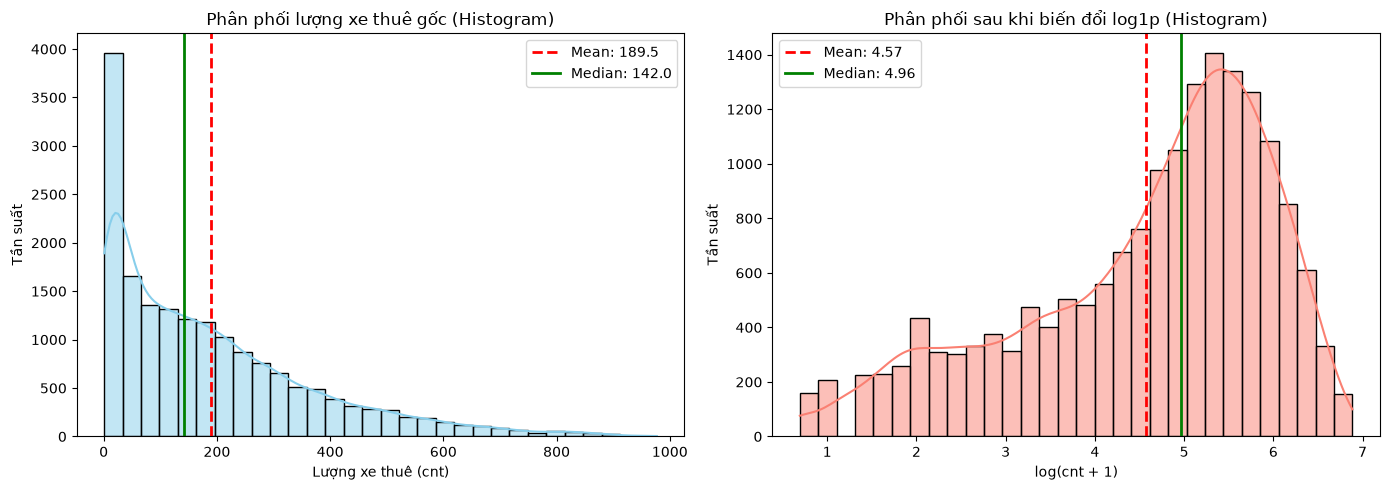

In [32]:
# Vẽ phân phối của cnt gốc và log1p(cnt) (Histogram)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Phân phối gốc
sns.histplot(df['cnt'], kde=True, ax=axes[0], color='skyblue', bins=30)
mean_val = df['cnt'].mean()
median_val = df['cnt'].median()
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.1f}')
axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.1f}')
axes[0].set_title('Phân phối lượng xe thuê gốc (Histogram)')
axes[0].set_xlabel('Lượng xe thuê (cnt)')
axes[0].set_ylabel('Tần suất')
axes[0].legend()

# Phân phối sau biến đổi log1p
log_cnt = np.log1p(df['cnt'])
sns.histplot(log_cnt, kde=True, ax=axes[1], color='salmon', bins=30)
axes[1].axvline(log_cnt.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {log_cnt.mean():.2f}')
axes[1].axvline(log_cnt.median(), color='green', linestyle='-', linewidth=2, label=f'Median: {log_cnt.median():.2f}')
axes[1].set_title('Phân phối sau khi biến đổi log1p (Histogram)')
axes[1].set_xlabel('log(cnt + 1)')
axes[1].set_ylabel('Tần suất')
axes[1].legend()

plt.tight_layout()
plt.savefig('../output/eda_1_histogram_log.png', dpi=300, bbox_inches='tight')
plt.show()

Biểu đồ cho thấy phân phối của `cnt` bị lệch phải khá nhiều, do giá trị trung bình (Mean = 189.5) lớn hơn trung vị (Median = 142.0). Khi áp dụng hàm `log1p`, đồ thị trở nên cân đối và gần với phân phối chuẩn hơn, giúp các mô hình hồi quy tuyến tính sau này ước lượng ổn định hơn.


# 6. Khảo sát các điểm ngoại lai theo mùa (Boxplot)


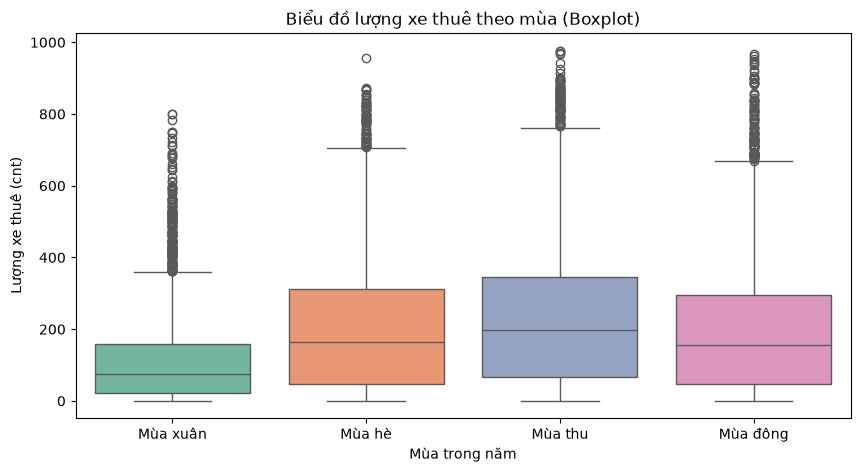

In [33]:
# Ánh xạ tên mùa để biểu đồ trực quan hơn
season_labels = {1: 'Mùa xuân', 2: 'Mùa hè', 3: 'Mùa thu', 4: 'Mùa đông'}
df['season_name'] = df['season'].map(season_labels)

plt.figure(figsize=(10, 5))
sns.boxplot(x='season_name', y='cnt', data=df, hue='season_name', palette='Set2', legend=False)
plt.title('Biểu đồ lượng xe thuê theo mùa (Boxplot)')
plt.xlabel('Mùa trong năm')
plt.ylabel('Lượng xe thuê (cnt)')

plt.savefig('../output/eda_2_boxplot_outliers.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
# Thống kê chính xác số lượng điểm ngoại lai theo từng mùa bằng phương pháp IQR
outlier_stats = []
for season in ['Mùa xuân', 'Mùa hè', 'Mùa thu', 'Mùa đông']:
    sub = df[df['season_name'] == season]['cnt']
    q1 = sub.quantile(0.25)
    median = sub.median()
    q3 = sub.quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    n_outliers = (sub > upper_bound).sum()
    pct = (n_outliers / len(sub)) * 100
    outlier_stats.append({
        'Mùa': season,
        'Tổng số giờ': len(sub),
        'Ngưỡng râu trên': round(upper_bound, 1),
        'Số ngoại lai': n_outliers,
        'Tỷ lệ (%)': f'{pct:.2f}%'
    })

outlier_df = pd.DataFrame(outlier_stats)
outlier_df

,Mùa,Tổng số giờ,Ngưỡng râu trên,Số ngoại lai,Tỷ lệ (%)
0,Mùa xuân,4242,360.5,195,4.60%
1,Mùa hè,4409,708.5,73,1.66%
2,Mùa thu,4496,760.5,98,2.18%
3,Mùa đông,4232,668.5,112,2.65%


Dùng tiêu chuẩn IQR, nhóm em tính được toàn bộ dữ liệu có 478 điểm ngoại lai (chiếm khoảng 2.75%). Trong đó, Mùa xuân (195 điểm) và Mùa đông (112 điểm) có số lượng ngoại lai nhiều nhất do mặt bằng chung thấp khiến ngưỡng trần bị hạ xuống. Mùa đông cũng ghi nhận có giờ thuê lên tới 967 xe, ngang ngửa mùa hè (968 xe) và mùa thu (977 xe). Các điểm ngoại lai này dễ làm mô hình nhạy lỗi như AdaBoost bị học vẹt (overfitting), nên nhóm em sẽ xử lý ở bước sau.


# 7. Phân tích xu hướng thuê xe theo 24 khung giờ


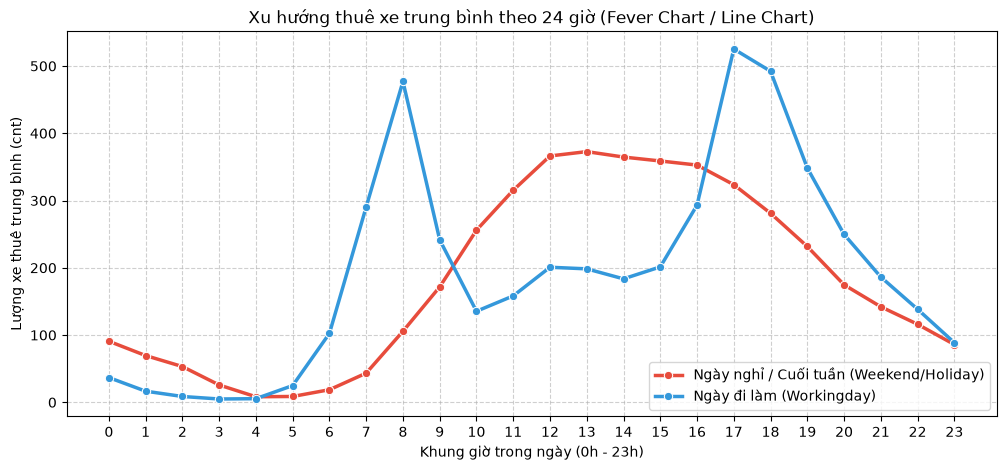

In [35]:
# Xu hướng thuê xe trung bình theo 24 giờ trong ngày (Fever chart / Line chart)
plt.figure(figsize=(12, 5))
working_df = df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()
working_df['workingday_name'] = working_df['workingday'].map({
    1: 'Ngày đi làm (Workingday)', 
    0: 'Ngày nghỉ / Cuối tuần (Weekend/Holiday)'
})

sns.lineplot(x='hr', y='cnt', hue='workingday_name', data=working_df, marker='o', linewidth=2.5, palette=['#e74c3c', '#3498db'])
plt.title('Xu hướng thuê xe trung bình theo 24 giờ (Fever Chart / Line Chart)')
plt.xlabel('Khung giờ trong ngày (0h - 23h)')
plt.ylabel('Lượng xe thuê trung bình (cnt)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='')
plt.savefig('../output/eda_3_time_trends.png', dpi=300, bbox_inches='tight')
plt.show()

Biểu đồ thể hiện rất rõ sự khác biệt giữa ngày đi làm và ngày nghỉ:
- **Ngày đi làm (đường màu xanh):** Có 2 đỉnh cao điểm rất rõ vào lúc 8h sáng (đi làm/đi học) và 17h-18h chiều (tan tầm về nhà).
- **Ngày nghỉ / Cuối tuần (đường màu đỏ):** Không có 2 đỉnh nhọn, mà nhu cầu tăng dần và đạt đỉnh vào giữa trưa khoảng 12h-16h để đi dạo, giải trí.
Sự khác biệt thực tế này là cơ sở để nhóm em tạo thêm đặc trưng mới `is_rush_hour` ở bước kỹ thuật đặc trưng.


# 8. Kiểm tra hiện tượng đa cộng tuyến và nguy cơ rò rỉ dữ liệu


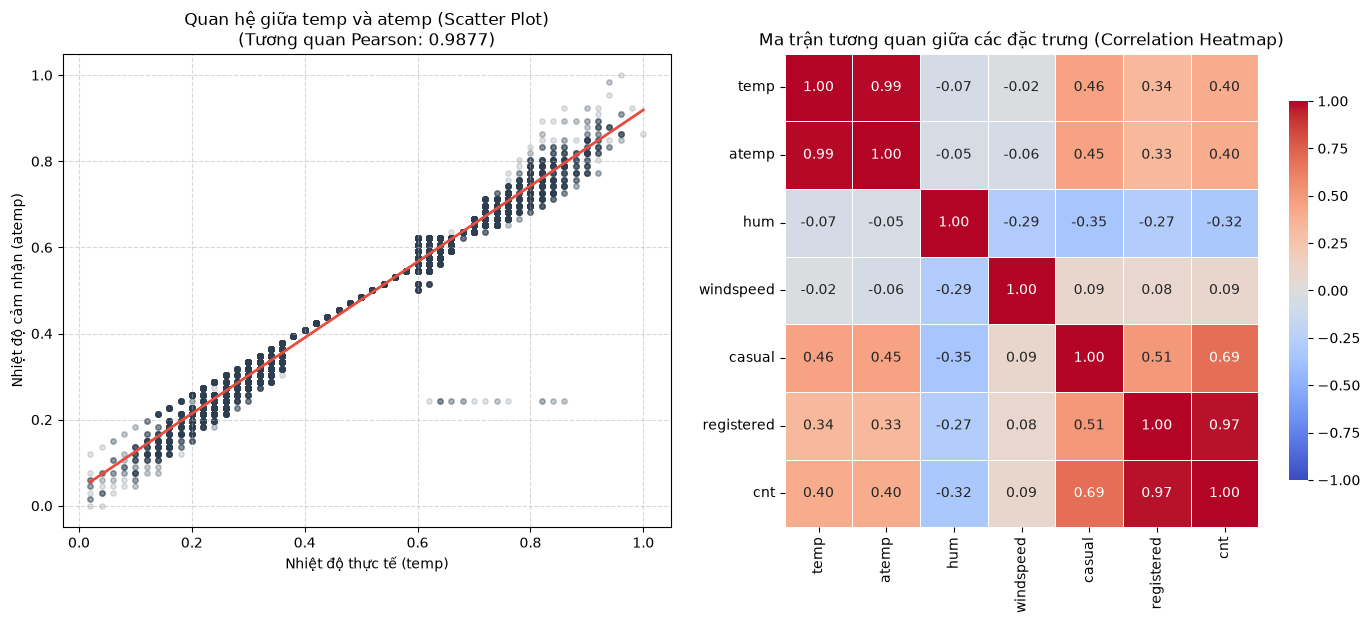

In [36]:
# Scatter plot và Correlation Heatmap kiểm tra đa cộng tuyến
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Quan hệ giữa temp và atemp (Scatter Plot)
corr_val = df['temp'].corr(df['atemp'])
sns.regplot(x='temp', y='atemp', data=df, ax=axes[0], color='#2c3e50', 
            scatter_kws={'alpha': 0.15, 's': 15}, line_kws={'color': '#e74c3c', 'linewidth': 2})
axes[0].set_title(f'Quan hệ giữa temp và atemp (Scatter Plot)\n(Tương quan Pearson: {corr_val:.4f})')
axes[0].set_xlabel('Nhiệt độ thực tế (temp)')
axes[0].set_ylabel('Nhiệt độ cảm nhận (atemp)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Correlation Heatmap
numeric_cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, 
            square=True, linewidths=0.5, ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Ma trận tương quan giữa các đặc trưng (Correlation Heatmap)')

plt.tight_layout()
plt.savefig('../output/eda_4_scatter_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Nhóm em nhận thấy hai vấn đề quan trọng cần xử lý:
1. **Hiện tượng đa cộng tuyến giữa `temp` và `atemp`:** Hệ số tương quan lên tới **0.99**, các điểm trên biểu đồ phân tán xếp thành một đường thẳng chéo. Trong hồi quy tuyến tính, đa cộng tuyến cao làm ma trận $(X^T X)$ gần suy biến khiến mô hình mất ổn định. Do đó, nhóm em sẽ bỏ cột `atemp` và chỉ giữ lại cột `temp`.
2. **Nguy cơ rò rỉ dữ liệu (Data Leakage):** Vì $cnt = casual + registered$, ma trận tương quan cho thấy `cnt` phụ thuộc gần như tuyệt đối vào hai cột này. Nếu không xóa `casual` và `registered` trước khi huấn luyện, mô hình sẽ bị rò rỉ kết quả và chỉ học phép cộng đơn giản thay vì học từ thời tiết và thời gian.


# 9. Phân tích chi tiết tác động của từng yếu tố thời tiết

Thời tiết là một trong hai trụ cột quan trọng nhất chi phối nhu cầu sử dụng xe đạp công cộng. Trong mục này, nhóm em tách riêng từng yếu tố thời tiết thành từng biểu đồ độc lập để khảo sát chi tiết:
- **Biến phân loại rời rạc (`weathersit`):** Sử dụng **Biểu đồ Hộp (Boxplot)** để khảo sát mức độ tập trung, tứ phân vị và độ lệch nhu cầu giữa 4 nhóm thời tiết.
- **Biến số học liên tục (`temp`, `hum`, `windspeed`):** Sử dụng **Biểu đồ phân tán (Scatter Plot)** kết hợp **Đường xu hướng hồi quy tuyến tính (Trendline)** để nhận diện chiều hướng tác động (thuận chiều / nghịch chiều) và cường độ tương quan Pearson.

### 9.1. Tác động của Loại thời tiết (weathersit) lên Lượng xe thuê (Boxplot)

In [ ]:
# Ánh xạ tên gọi chi tiết cho các nhóm thời tiết
ws_labels = {
    1: '1: Nắng / Ít mây',
    2: '2: Sương mù / U ám',
    3: '3: Mưa nhỏ / Tuyết nhẹ',
    4: '4: Mưa to / Bão'
}
df['ws_label'] = df['weathersit'].map(ws_labels)
order = ['1: Nắng / Ít mây', '2: Sương mù / U ám', '3: Mưa nhỏ / Tuyết nhẹ', '4: Mưa to / Bão']
present_order = [o for o in order if o in df['ws_label'].unique()]

plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, x='ws_label', y='cnt', hue='ws_label', order=present_order, palette='Blues', legend=False)
plt.title('Biểu đồ lượng xe thuê theo Loại thời tiết (Boxplot)', fontsize=13, fontweight='bold')
plt.xlabel('Hình thái thời tiết (weathersit)', fontsize=11)
plt.ylabel('Lượng xe thuê theo giờ (cnt)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.savefig('../output/eda_5a_weather_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét (weathersit):**
- Điều kiện thời tiết ảnh hưởng rõ rệt đến hành vi đi lại: Lượng xe thuê trung bình đạt cao nhất vào những ngày trời nắng, quang đãng (**204.9 xe/giờ**), giảm xuống **175.2 xe/giờ** khi trời u ám có sương mù, và sụt giảm mạnh chỉ còn **111.6 xe/giờ** khi có mưa nhỏ hoặc tuyết rơi.
- Trường hợp thời tiết cực đoan cấp 4 (Mưa to, giông bão tuyết) rất hiếm xảy ra trong 2 năm (chỉ có 3 giờ ghi nhận) với lượng thuê trung bình rơi xuống đáy **74.3 xe/giờ**.

### 9.2. Mối liên hệ giữa Nhiệt độ (temp) và Lượng xe thuê (Scatter Plot)

In [ ]:
r_temp = df['temp'].corr(df['cnt'])

plt.figure(figsize=(10, 5.5))
plt.scatter(df['temp'], df['cnt'], alpha=0.25, color='#e07b39', s=12, edgecolors='none', label='Quan sát (17,379 giờ)')

# Đường xu hướng hồi quy tuyến tính
z_temp = np.polyfit(df['temp'], df['cnt'], 1)
p_temp = np.poly1d(z_temp)
x_temp = np.linspace(df['temp'].min(), df['temp'].max(), 200)
plt.plot(x_temp, p_temp(x_temp), color='darkred', linewidth=2.5, label=f'Đường xu hướng hồi quy (r = +{r_temp:.2f})')

plt.title('Mối liên hệ giữa Nhiệt độ và Lượng xe thuê (Scatter Plot)', fontsize=13, fontweight='bold')
plt.xlabel('Nhiệt độ môi trường chuẩn hóa (temp)', fontsize=11)
plt.ylabel('Lượng xe thuê theo giờ (cnt)', fontsize=11)
plt.legend(frameon=True, loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)

plt.savefig('../output/eda_5b_temp_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét (temp):**
- Hệ số tương quan Pearson $r = +0.40$ chỉ ra mối quan hệ **tương quan thuận chiều rõ rệt** giữa nhiệt độ và lượng xe thuê.
- Khi nhiệt độ ấm dần lên từ ngưỡng rét buốt ($temp < 0.2$, xấp xỉ $< 0^\circ\text{C}$), nhu cầu thuê xe tăng vọt mạnh mẽ. Đây là đặc trưng thời tiết liên tục có sức ảnh hưởng dự báo lớn nhất đến biến mục tiêu.

### 9.3. Mối liên hệ giữa Độ ẩm (hum) và Lượng xe thuê (Scatter Plot)

In [ ]:
r_hum = df['hum'].corr(df['cnt'])

plt.figure(figsize=(10, 5.5))
plt.scatter(df['hum'], df['cnt'], alpha=0.25, color='#2ca02c', s=12, edgecolors='none', label='Quan sát (17,379 giờ)')

# Đường xu hướng hồi quy tuyến tính
z_hum = np.polyfit(df['hum'], df['cnt'], 1)
p_hum = np.poly1d(z_hum)
x_hum = np.linspace(df['hum'].min(), df['hum'].max(), 200)
plt.plot(x_hum, p_hum(x_hum), color='darkgreen', linewidth=2.5, label=f'Đường xu hướng hồi quy (r = {r_hum:.2f})')

plt.title('Mối liên hệ giữa Độ ẩm và Lượng xe thuê (Scatter Plot)', fontsize=13, fontweight='bold')
plt.xlabel('Độ ẩm không khí chuẩn hóa (hum)', fontsize=11)
plt.ylabel('Lượng xe thuê theo giờ (cnt)', fontsize=11)
plt.legend(frameon=True, loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)

plt.savefig('../output/eda_5c_hum_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét (hum):**
- Hệ số tương quan Pearson $r = -0.32$ thể hiện mối quan hệ **tương quan nghịch chiều**.
- Khi độ ẩm không khí tăng cao ($hum > 0.8$, tức $> 80\%$), không khí trở nên ẩm ướt hoặc kèm mưa phùn oi bức, khiến mức độ thoải mái khi đạp xe giảm mạnh, dẫn đến lượng khách thuê xe sụt giảm rõ rệt.

### 9.4. Mối liên hệ giữa Tốc độ gió (windspeed) và Lượng xe thuê (Scatter Plot)

In [ ]:
r_wind = df['windspeed'].corr(df['cnt'])

plt.figure(figsize=(10, 5.5))
plt.scatter(df['windspeed'], df['cnt'], alpha=0.25, color='#9467bd', s=12, edgecolors='none', label='Quan sát (17,379 giờ)')

# Đường xu hướng hồi quy tuyến tính
z_wind = np.polyfit(df['windspeed'], df['cnt'], 1)
p_wind = np.poly1d(z_wind)
x_wind = np.linspace(df['windspeed'].min(), df['windspeed'].max(), 200)
plt.plot(x_wind, p_wind(x_wind), color='indigo', linewidth=2.5, label=f'Đường xu hướng hồi quy (r = +{r_wind:.2f})')

plt.title('Mối liên hệ giữa Tốc độ gió và Lượng xe thuê (Scatter Plot)', fontsize=13, fontweight='bold')
plt.xlabel('Tốc độ gió chuẩn hóa (windspeed)', fontsize=11)
plt.ylabel('Lượng xe thuê theo giờ (cnt)', fontsize=11)
plt.legend(frameon=True, loc='upper right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.4)

plt.savefig('../output/eda_5d_windspeed_scatter.png', dpi=300, bbox_inches='tight')
plt.show()

**Nhận xét (windspeed):**
- Hệ số tương quan Pearson $r = +0.09$ khá yếu, cho thấy quan hệ tuyến tính giữa gió và lượng thuê không đáng kể ở các dải gió bình thường.
- Tuy nhiên, khi tốc độ gió đạt ngưỡng rất lớn ($windspeed > 0.5$, tức $> 33.5\text{ km/h}$), số lượng quan sát có lượng thuê cao giảm hẳn do gió lớn cản trở việc đạp xe an toàn.

# 10. Heatmap tương tác giờ trong ngày × loại thời tiết (hr × weathersit)

In [ ]:
# Tính lượng xe thuê trung bình theo từng (giờ, loại thời tiết)
pivot = df.groupby(['hr', 'weathersit'])['cnt'].mean().unstack()
pivot.columns = ['1: Nắng / Ít mây', '2: Sương mù / U ám', '3: Mưa nhỏ / Tuyết nhẹ', '4: Mưa to / Bão']

plt.figure(figsize=(10, 10))
sns.heatmap(
    pivot, annot=True, fmt='.0f',
    cmap='YlOrRd', linewidths=0.4,
    cbar_kws={'label': 'Lượng xe thuê trung bình (cnt)'}
)
plt.title('Heatmap: Lượng xe thuê trung bình theo Giờ × Loại thời tiết\n(Heatmap kết hợp hr × weathersit)',
          fontsize=13, fontweight='bold')
plt.xlabel('Hình thái thời tiết (weathersit)', fontsize=11)
plt.ylabel('Giờ trong ngày (hr)', fontsize=11)
plt.yticks(ticks=np.arange(24) + 0.5, labels=[f'{h:02d}:00' for h in range(24)], rotation=0, fontsize=9)

plt.tight_layout()
plt.savefig('../output/eda_6_time_weather_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

Biểu đồ Heatmap cho thấy sự tương tác giữa khung giờ và điều kiện thời tiết ảnh hưởng rất rõ đến lượng xe thuê:
- Vào giờ cao điểm sáng (08h) và chiều (17h-18h), dưới điều kiện thời tiết lý tưởng (`weathersit=1`), lượng xe thuê trung bình đạt tới **443.6 xe/giờ**. Nhưng khi thời tiết xấu có mưa/tuyết (`weathersit=3`), con số này rơi tự do xuống chỉ còn **256.5 xe/giờ** — tức **giảm hơn 42%** ngay trong cùng một khung giờ.
- Nhu cầu ban đêm (0h - 5h) gần như bị triệt tiêu về đáy bất kể thời tiết đẹp hay xấu, chứng tỏ yếu tố nhịp sinh học ban đêm áp đảo hoàn toàn yếu tố thời tiết.
- Phát hiện này củng cố tính cấp thiết của việc xây dựng các đặc trưng tương tác kết hợp giữa thời gian và thời tiết ở giai đoạn tiếp theo.